## 6. Apprentissage d'un RNN sur le corpus de texte Victor HUGO

```
Objectif: Prédire le mot suivant à partir des 3 mots précédents, puis un texte mots après mot. Les exemples d'entraînement et la génération utilisent le même format: une fenétre de 3 mots, complétée par des zéros au début si besoin
```

In [1]:
#importing libraries from libs.py

from libs import *        # np, pd, plt, tf, keras, layers, train_test_split, ...

In [2]:
with open('victor-hugo-texts.txt', 'r', encoding='utf-8') as f:
    texts = [line.strip() for line in f if line.strip() != '']
    
print(f"Exemple de texte: {texts[0]}")

Exemple de texte: Mes vers fuiraient


In [3]:
vocab = 1000
window_size = 3

tokenizer = tf.keras.preprocessing.text.Tokenizer(num_words=vocab)
tokenizer.fit_on_texts(texts)
sequences = tokenizer.texts_to_sequences(texts)

In [4]:
X = []
y = []

for seq in sequences:
    for i in range(1, len(seq)):
        X.append(seq[max(0, i - window_size):i])
        y.append(seq[i])

X = tf.keras.preprocessing.sequence.pad_sequences(
    X, maxlen=window_size, padding="pre"
)
y = np.array(y)

print(f"X shape: {X.shape}, y shape: {y.shape}")

X shape: (11541, 3), y shape: (11541,)


In [5]:
embedding_dim = 16

model = keras.Sequential([
    keras.layers.Embedding(input_dim=vocab, output_dim=embedding_dim),
    keras.layers.SimpleRNN(32),
    keras.layers.Dense(vocab, activation="softmax")
])

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [6]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="loss",
    patience=10,
    restore_best_weights=True
)
history = model.fit(
    X, y, 
    epochs=500,
    batch_size=32,
    callbacks=[early_stop]
)

Epoch 1/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.0344 - loss: 6.1440
Epoch 2/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0364 - loss: 5.8559
Epoch 3/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0387 - loss: 5.7679
Epoch 4/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0458 - loss: 5.6619
Epoch 5/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0517 - loss: 5.5707
Epoch 6/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0557 - loss: 5.4927
Epoch 7/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0673 - loss: 5.4202
Epoch 8/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.0707 - loss: 5.3449
Epoch 9/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0782 - loss: 5.2728
Epoch 10/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0853 - loss: 5.2004
Epoch 11/500
361/361 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.0891 - loss: 5.1276
Epoch 12/500
361/361 ━━━━━━━━━━━━━━━━━━━━

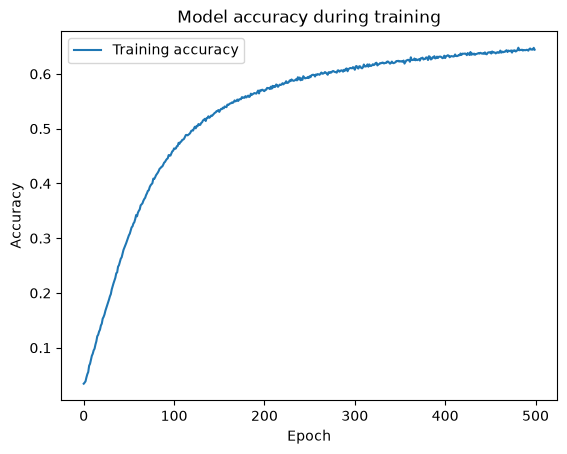

In [11]:
# Analyse de performance du model en graph
import matplotlib.pyplot as plt

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.title("Model accuracy during training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

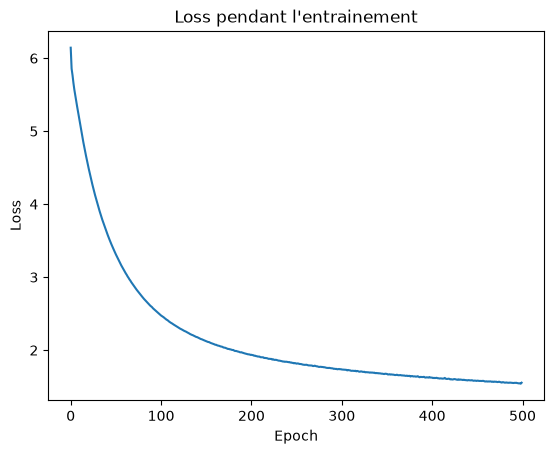

In [7]:
plt.plot(history.history['loss'])
plt.title('Loss pendant l\'entrainement')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

##### Visualiser la prédiction pour quelques exemples

In [27]:
# x_test is already normalized and shaped (N, 28, 28, 1)
probs = model.predict(X, batch_size=256, verbose=0)
top5 = np.argsort(probs, axis=1)[:, -5:]
print("Top-1 :", np.mean(y_pred == y))
print("Top-5 :", np.mean([y[i] in top5[i] for i in range(len(y))]))

Top-1 : 0.6617277532276232
Top-5 : 0.8401351702625423


#### Matrix confusion

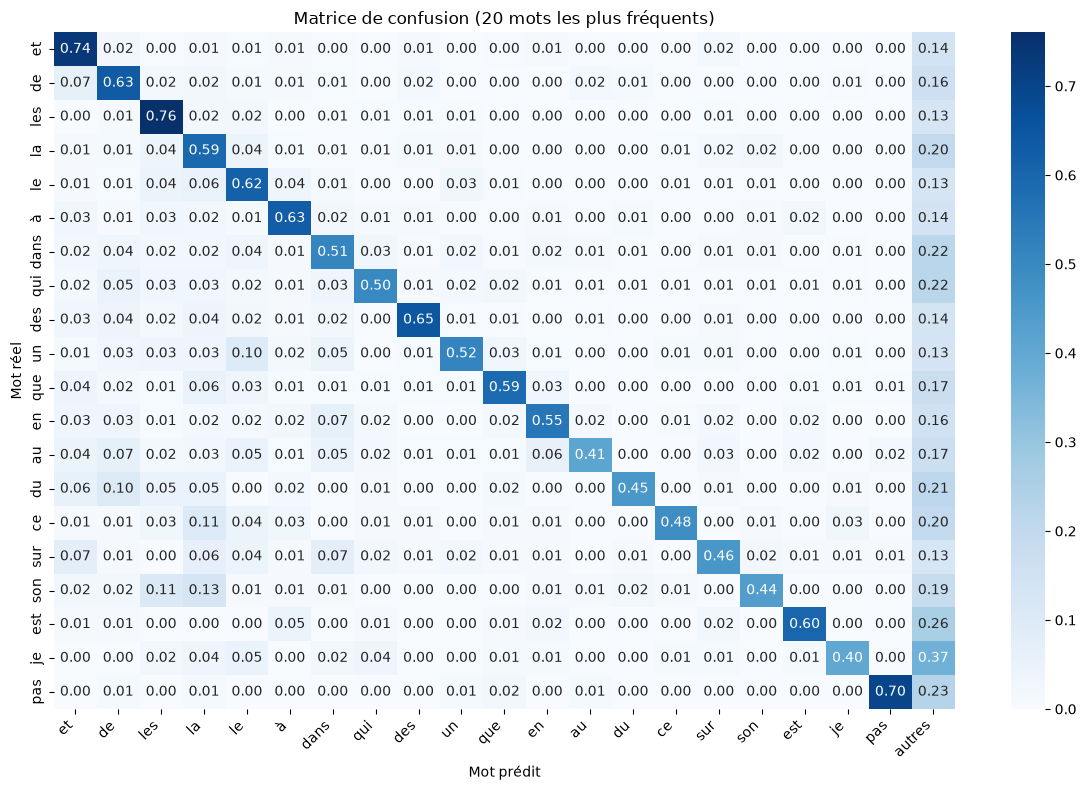

In [24]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

y_pred = np.argmax(model.predict(X, batch_size=256, verbose=0), axis=1)

top_n = 20
freq = np.bincount(y, minlength=vocab)
top_ids = np.argsort(freq)[::-1][:top_n]
labels = [tokenizer.index_word.get(i, str(i)) for i in top_ids]

# keep samples whose true word is in the top N; other predictions become "autres" (-1)
mask = np.isin(y, top_ids)
y_true = y[mask]
y_hat = np.where(np.isin(y_pred[mask], top_ids), y_pred[mask], -1)

cm = confusion_matrix(y_true, y_hat, labels=list(top_ids) + [-1])[:-1]  # drop the empty "autres" row
cm_norm = cm / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(12, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=labels + ["autres"], yticklabels=labels)
plt.xlabel("Mot prédit")
plt.ylabel("Mot réel")
plt.title(f"Matrice de confusion ({top_n} mots les plus fréquents)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [26]:
errors = pd.Series(list(zip(
    [tokenizer.index_word.get(i) for i in y[y != y_pred]],
    [tokenizer.index_word.get(i) for i in y_pred[y != y_pred]]
))).value_counts().head(10)
print(errors)

(de, et)       24
(le, la)       19
(la, le)       15
(le, les)      15
(un, le)       15
(leurs, la)    15
(la, les)      14
(leur, les)    13
(le, à)        13
(son, la)      12
Name: count, dtype: int64


In [29]:
from sklearn.metrics import classification_report

top_n = 100
freq = np.bincount(y, minlength=vocab)
top_ids = np.argsort(freq)[::-1][:top_n]          # 100 most frequent target words
names = [tokenizer.index_word.get(i, str(i)) for i in top_ids]

print(classification_report(
    y, y_pred,
    labels=top_ids,
    target_names=names,
    zero_division=0
))

              precision    recall  f1-score   support

          et       0.65      0.74      0.69       428
          de       0.54      0.63      0.59       365
         les       0.57      0.76      0.65       363
          la       0.40      0.59      0.48       360
          le       0.52      0.62      0.57       338
           à       0.54      0.63      0.58       207
        dans       0.47      0.51      0.49       191
         qui       0.53      0.50      0.52       181
         des       0.66      0.65      0.65       172
          un       0.55      0.52      0.53       149
         que       0.53      0.59      0.56       145
          en       0.60      0.55      0.58       121
          au       0.53      0.41      0.46       119
          du       0.58      0.45      0.51        99
          ce       0.64      0.48      0.55        95
         sur       0.45      0.46      0.45        94
         son       0.54      0.44      0.48        91
         est       0.57    

In [31]:
def generate_text(start_text, num_words=50, temperature=0.80):
    text = start_text
    for _ in range(num_words):
        #même format qu'à l'entrainement: les 3 derniers mots seulement
        tokens = tokenizer.texts_to_sequences([text])[0][-window_size:]
        tokens = pad_sequences([tokens], maxlen=window_size, padding='pre')
        #probablities du mot suivant
        probs = model.predict(tokens, verbose=0)[0]
        #Tirage pondéré(temperature <1 : plus sûr, >1 : plus varié)
        probs = np.exp(np.log(probs + 1e-9) /temperature)
        probs /= probs.sum()
        index = np.random.choice(len(probs), p=probs)
        
        word = tokenizer.index_word.get(index)
        
        if word is not None:
            text += ' ' +word
            
    return text 

In [32]:
pad_sequences = tf.keras.preprocessing.sequence.pad_sequences
random_text = generate_text("Ce siècle avait deux ans", num_words=50)
print(random_text)

Ce siècle avait deux ans déjà sous l'ombre quoique les d'une joyeuse comprendre l'air comme un doit contre nos s'ils se le farouche rire de rond dragons – rien le certes se que peine non rois décroît qui le ciel est vous qu'il je soit une soit maudit et te à ô chercher dans l'ombre
